# 02. Huấn Luyện Random Forest (`random_forest.joblib`)
Mô hình rừng ngẫu nhiên **Random Forest Classifier** (`n_estimators=120, max_depth=10, min_samples_leaf=15`). Artifact xuất ra `/notebook/model/random_forest.joblib`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

from src.config import settings
from src.models.datasets import DATASETS, load_dataframe, mask_augment
from src.storage.db import engine

spec = DATASETS["nhanes"]
df = load_dataframe(spec, engine)
X, y = df[spec.features].astype(float), df[spec.label].astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_tr_aug, y_tr_aug = mask_augment(X_tr, y_tr, spec, p=0.4, seed=42)

rf = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=120, max_depth=10, min_samples_leaf=15, n_jobs=-1, random_state=42),
)
rf.fit(X_tr_aug, y_tr_aug)
artifact_path = settings.model_dir / "random_forest.joblib"
joblib.dump(rf, artifact_path)

p_te = rf.predict_proba(X_te)[:, 1]
print(f"Đã lưu artifact: {artifact_path.relative_to(ROOT)}")
print(f"ROC-AUC: {roc_auc_score(y_te, p_te):.4f} | PR-AUC: {average_precision_score(y_te, p_te):.4f} | Brier: {brier_score_loss(y_te, p_te):.4f}")

Đã lưu artifact: notebook/model/random_forest.joblib
ROC-AUC: 0.8185 | PR-AUC: 0.5116 | Brier: 0.1243


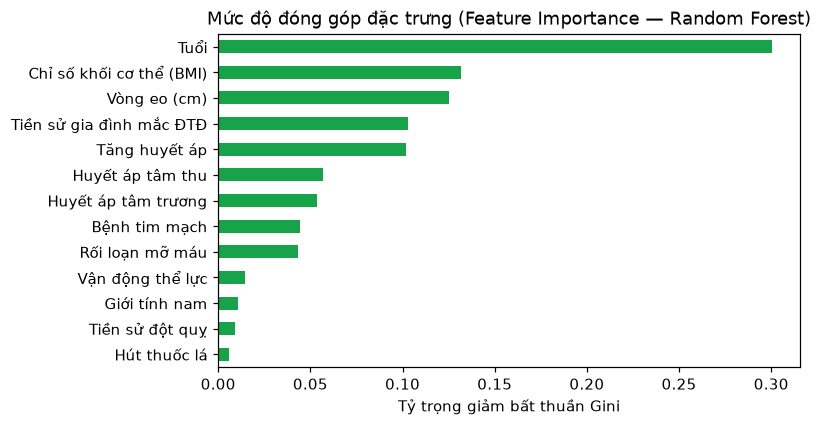

In [2]:
# Độ quan trọng đặc trưng (Gini Importance) của Random Forest
imp = pd.Series(rf.named_steps["randomforestclassifier"].feature_importances_, index=[spec.feature_vi[f] for f in spec.features]).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4))
imp.plot(kind="barh", color="#16a34a", ax=ax)
ax.set_title("Mức độ đóng góp đặc trưng (Feature Importance — Random Forest)")
ax.set_xlabel("Tỷ trọng giảm bất thuần Gini")
plt.tight_layout()